In [ ]:
import math
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

LR_DIR = Path('../esrgan_val_lr')
LR_DEGRADED_DIR = Path('../esrgan_val_lr_degraded')
HR_DIR = Path('../esrgan_val_hr')
# during training BasicSR saves SR as visualization/<name>/<name>_<iter>.png;
# both val sets share file names, so only the last one (degraded) is kept on disk
SR_DIR = Path('../esrgan_vis')
# inference_realesrgan.py outputs: <model>/<val_lr | val_lr_degraded>/<name>.png
BASELINE_DIR = Path('../results/baseline')
FINETUNED_DIR = Path('../results/finetuned_10k')

# every random_name() call gives a new patch, and the sequence repeats after re-running this cell
SEED = 0
rng = random.Random(SEED)


def random_name():
    return rng.choice(sorted(p.stem for p in HR_DIR.glob('*.png')))


def saved_iterations(name):
    return sorted(int(re.search(r'_(\d+)$', p.stem).group(1)) for p in (SR_DIR / name).glob(f'{name}_*.png'))


def psnr(image, reference):
    mse = np.mean((np.asarray(image, float) - np.asarray(reference, float)) ** 2)
    return 10 * np.log10(255 ** 2 / mse)


def show_lr_hr_sr(name, iteration=None, figsize=(20, 5)):
    """Show LR (bicubic), LR (degraded), SR at the given iteration and HR; iteration=None takes the latest one."""
    saved = saved_iterations(name)
    print(f'{name}: SR saved at iterations {saved}')
    iteration = saved[-1] if iteration is None else iteration

    lr, lr_degraded, hr, sr = (Image.open(p).convert('RGB') for p in (
        LR_DIR / f'{name}.png',
        LR_DEGRADED_DIR / f'{name}.png',
        HR_DIR / f'{name}.png',
        SR_DIR / name / f'{name}_{iteration}.png',
    ))
    panels = [
        (lr.resize(hr.size, Image.NEAREST), f'LR bicubic {lr.width}x{lr.height}'),
        (lr_degraded.resize(hr.size, Image.NEAREST), f'LR degraded {lr_degraded.width}x{lr_degraded.height}'),
        (sr, f'SR @ iter {iteration}'),
        (hr, f'HR {hr.width}x{hr.height}'),
    ]
    fig, axes = plt.subplots(1, 4, figsize=figsize)
    for ax, (image, title) in zip(axes, panels):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()


def show_sr_iterations(name, ncols=6, tile_size=3.5):
    """Show LR (degraded), SR at every saved iteration and HR in a grid, to see how the output changes during training."""
    hr = Image.open(HR_DIR / f'{name}.png').convert('RGB')
    lr_degraded = Image.open(LR_DEGRADED_DIR / f'{name}.png').convert('RGB')
    panels = [(lr_degraded.resize(hr.size, Image.NEAREST), 'LR degraded')]
    panels += [(Image.open(SR_DIR / name / f'{name}_{it}.png').convert('RGB'), f'SR @ iter {it}')
               for it in saved_iterations(name)]
    panels.append((hr, 'HR'))

    nrows = math.ceil(len(panels) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * tile_size, nrows * tile_size), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, (image, title) in zip(axes.flat, panels):
        ax.imshow(image)
        ax.set_title(title)
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()


def show_baseline_vs_finetuned(name, tile_size=4.5):
    """For both inputs (bicubic, degraded) show LR, SR of the original model, SR of the finetuned one and HR.

    PSNR in the titles is computed against HR over the whole image.
    """
    hr = Image.open(HR_DIR / f'{name}.png').convert('RGB')
    inputs = [('val_lr', LR_DIR, 'bicubic'), ('val_lr_degraded', LR_DEGRADED_DIR, 'degraded')]

    fig, axes = plt.subplots(len(inputs), 4, figsize=(4 * tile_size, len(inputs) * tile_size), squeeze=False)
    for row, (folder, lr_dir, label) in zip(axes, inputs):
        lr = Image.open(lr_dir / f'{name}.png').convert('RGB')
        baseline = Image.open(BASELINE_DIR / folder / f'{name}.png').convert('RGB')
        finetuned = Image.open(FINETUNED_DIR / folder / f'{name}.png').convert('RGB')
        panels = [
            (lr.resize(hr.size, Image.NEAREST), f'LR {label}'),
            (baseline, f'Baseline, PSNR {psnr(baseline, hr):.2f}'),
            (finetuned, f'Finetuned, PSNR {psnr(finetuned, hr):.2f}'),
            (hr, 'HR'),
        ]
        for ax, (image, title) in zip(row, panels):
            ax.imshow(image)
            ax.set_title(title)
            ax.axis('off')
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

In [60]:
name = random_name()
print(name)

40563_Crop_10_y384_x0


40563_Crop_10_y384_x0: SR saved at iterations [5000, 10000, 15000, 20000, 25000, 30000]


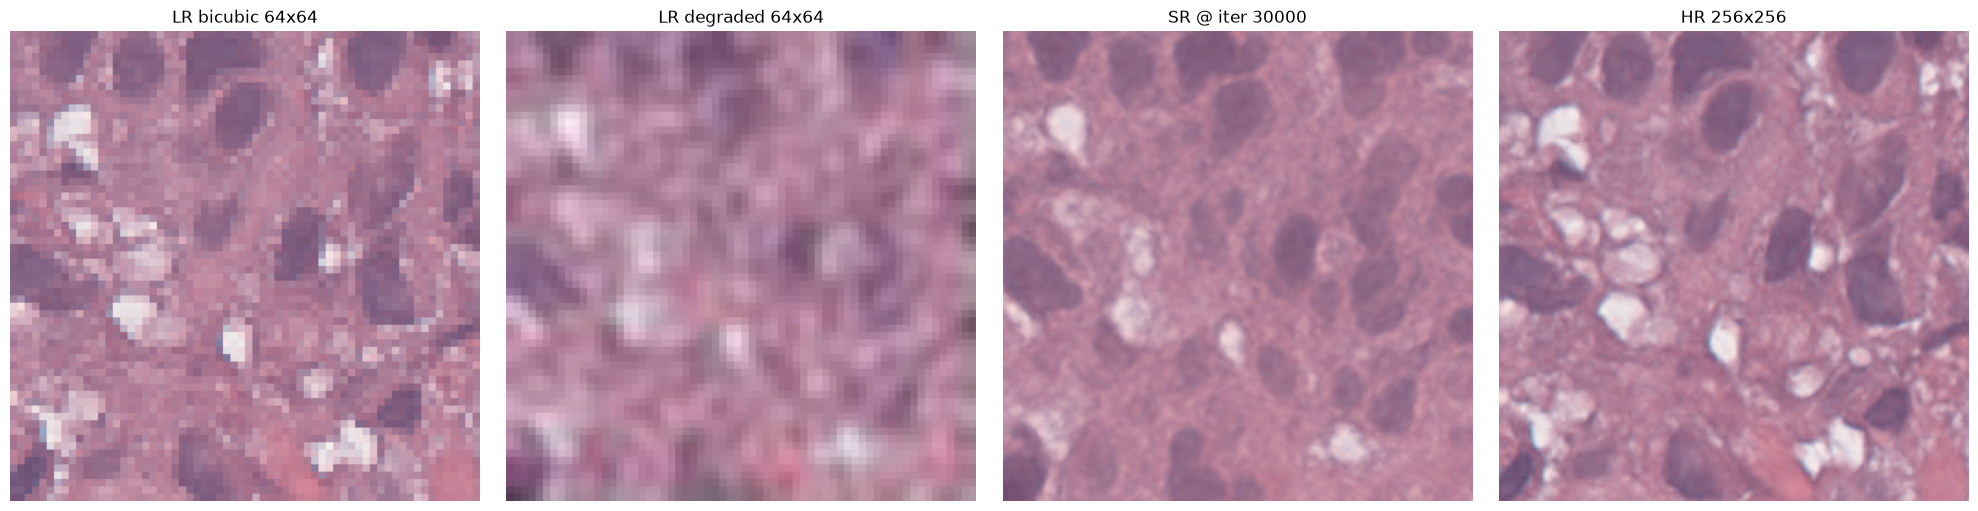

In [61]:
show_lr_hr_sr(name)

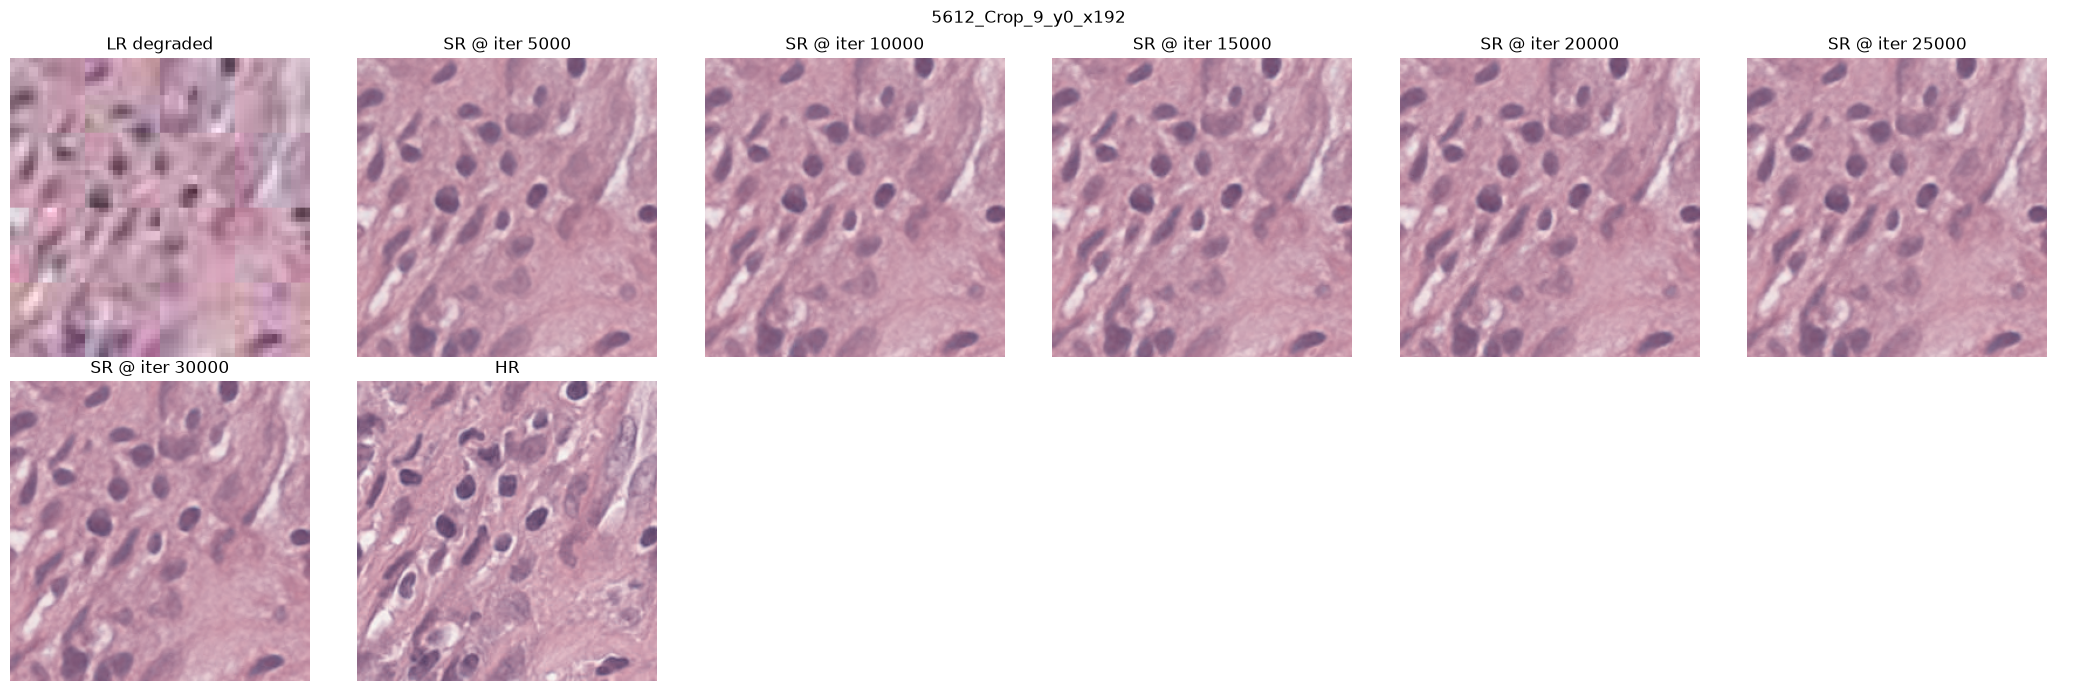

In [58]:
show_sr_iterations(name)

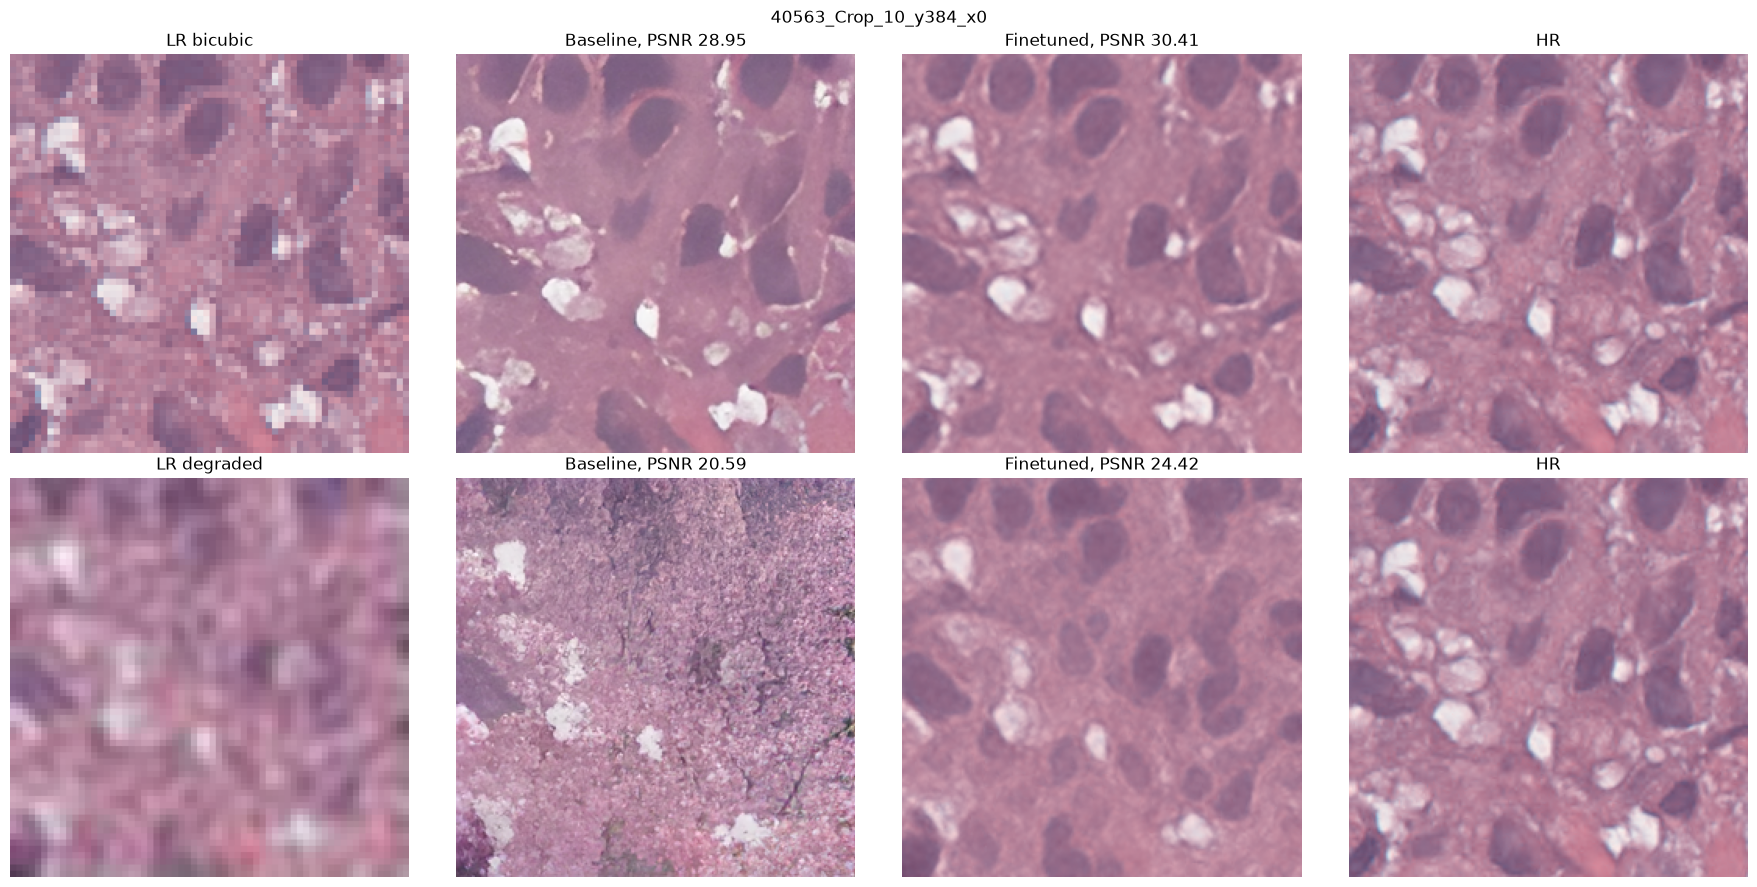

In [62]:
show_baseline_vs_finetuned(name)